# Fraudulent Bitcoin Transaction Detection — BT4012

**Task.** Classify Bitcoin transactions as illicit (1) or licit (0) and output a probability
`P(illicit)` for each test transaction, scored by **ROC-AUC**. The data is the Elliptic dataset:
each transaction is a node with 165 anonymized features and a `time_step`; transactions are linked
in a payment-flow graph (`txs_edgelist.csv`).

**Why it matters.** This mirrors a real anti-money-laundering (AML) problem: surface likely-illicit
activity for investigators while keeping false alarms manageable. ROC-AUC rewards *ranking* illicit
above licit rather than any fixed threshold, which suits a triage/prioritisation setting.

**Core difficulties and how we address them.**
1. *Severe class imbalance* — illicit is a small minority of labeled rows. We use class/scale
   weighting and evaluate with AUC (threshold-free).
2. *Mostly-unlabeled pool* — ~78% of train rows are unlabeled. We exploit them as **graph
   structure** (neighbor aggregates) rather than for cross-boundary label flow.
3. *Temporal generalization* — test is strictly **future** time steps. We validate on a **temporal
   holdout** (latest labeled steps), never a random split.

**Approach.** Gradient-boosted trees (LightGBM, XGBoost) and a random forest on the 165 raw
features plus engineered graph features (degree, 1-hop neighbor aggregates). The final submission
is a **rank-average blend of three diverse learners** (LightGBM + XGBoost + Random Forest) with
mild recency weighting — chosen because, on the public leaderboard (the real future steps), learner
diversity drove the biggest gain and a blend is more robust to the future-time distribution shift
than any single model.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from scipy.stats import rankdata
import networkx as nx
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import xgboost as xgb

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

# Resolve data dir whether the notebook runs from repo root or notebooks/.
DATA_DIR = next(p for p in [Path("data/raw"), Path("../data/raw")] if p.exists())
SUB_DIR = DATA_DIR.parent.parent / "submissions"
SUB_DIR.mkdir(exist_ok=True)
print("data dir:", DATA_DIR.resolve())

ALL_FEATS = [f"feat_{i}" for i in range(1, 166)]
# Local (per-transaction) feature block to build neighbor aggregates over; the
# remaining feats are the dataset's own aggregates (less useful to re-aggregate).
LOCAL_FEATS = [f"feat_{i}" for i in range(1, 94)]
VAL_START_STEP = 31  # temporal holdout: train on steps < 31, validate on 31..35
RECENCY_GAMMA = 0.10  # recency weight w(t) = exp(gamma * (t - t_max)); recent steps weigh more

data dir: /Users/I777832/bt4012_competition/data/raw


## 2. Load data and exploratory analysis

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
print(f"train={train.shape}  test={test.shape}  edges={edges.shape}")

print("\nLabel distribution (train):")
print(train["label"].value_counts(dropna=False).rename({1.0: "illicit", 0.0: "licit"}))
labeled_rate = train["label"].notna().mean()
illicit_rate = train.loc[train["label"].notna(), "label"].mean()
print(f"\nlabeled fraction = {labeled_rate:.3f} | illicit rate among labeled = {illicit_rate:.3f}")
print(f"train time_steps = {train.time_step.min()}..{train.time_step.max()} | "
      f"test time_steps = {test.time_step.min()}..{test.time_step.max()}")

train=(141772, 168)  test=(15329, 168)  edges=(234355, 2)

Label distribution (train):
label
NaN        110537
licit       27591
illicit      3644
Name: count, dtype: int64

labeled fraction = 0.220 | illicit rate among labeled = 0.117
train time_steps = 1..35 | test time_steps = 36..49


### 2.1 Illicit rate over time

Illicit prevalence is not constant across time steps. Because the test set is entirely in the
future (steps 36–49), a model must stay calibrated as this mix drifts.

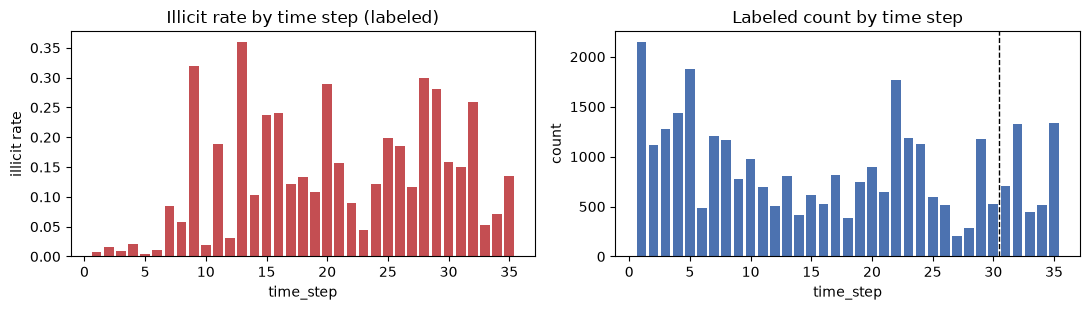

In [3]:
lab = train[train["label"].notna()]
by_step = lab.groupby("time_step")["label"].agg(["mean", "size"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar(by_step.index, by_step["mean"], color="#C44E52")
ax[0].set_title("Illicit rate by time step (labeled)"); ax[0].set_xlabel("time_step"); ax[0].set_ylabel("illicit rate")
ax[1].bar(by_step.index, by_step["size"], color="#4C72B0")
ax[1].axvline(VAL_START_STEP - 0.5, color="k", ls="--", lw=1)
ax[1].set_title("Labeled count by time step"); ax[1].set_xlabel("time_step"); ax[1].set_ylabel("count")
plt.tight_layout(); plt.show()

### 2.2 The graph is partitioned by time

An edge `txId1 → txId2` means an output of transaction `txId1` is spent as an input of `txId2`.
In the Elliptic data, **connected transactions share a time step**, so the graph splits into
per-time-step components. We verify that **no edge crosses the train/test boundary** — a crucial
fact: it means we cannot propagate labels through the graph from train into test, and any graph
signal is inherently *within a time step*. The unlabeled transactions are therefore valuable as
**structure** (richer neighborhoods for aggregation), not as a label bridge.

In [4]:
train_ids, test_ids = set(train.txId), set(test.txId)
src_in_train = edges.txId1.isin(train_ids); dst_in_test = edges.txId2.isin(test_ids)
src_in_test = edges.txId1.isin(test_ids); dst_in_train = edges.txId2.isin(train_ids)
cross = int(((src_in_train & dst_in_test) | (src_in_test & dst_in_train)).sum())
edge_nodes = set(edges.txId1) | set(edges.txId2)
print(f"edges crossing train<->test: {cross}")
print(f"train nodes in edgelist: {len(train_ids & edge_nodes)}/{len(train_ids)}")
print(f"test  nodes in edgelist: {len(test_ids & edge_nodes)}/{len(test_ids)}")
print(f"background nodes (in graph, neither train nor test): {len(edge_nodes - train_ids - test_ids)}")

edges crossing train<->test: 0
train nodes in edgelist: 141772/141772
test  nodes in edgelist: 15329/15329
background nodes (in graph, neither train nor test): 46668


## 3. Feature engineering: graph features

We add two families of graph features to the 165 raw features, computed once over the **full** edge
list (so "background" nodes still contribute to a node's degree):

* **Degree features** — in/out/total degree and ratios. Note degree ≠ the raw Bitcoin input/output
  counts (those are already among `feat_*`); it measures observed-graph connectivity.
* **Neighbor aggregates** — mean/std of the local feature block over each node's 1-hop predecessors
  and successors. Only neighbors that carry features (train/test nodes) contribute values.

In [5]:
def degree_features(edges):
    out_deg = edges.groupby("txId1").size().rename("out_degree")
    in_deg = edges.groupby("txId2").size().rename("in_degree")
    deg = pd.concat([out_deg, in_deg], axis=1).fillna(0.0)
    deg["total_degree"] = deg["in_degree"] + deg["out_degree"]
    deg["in_out_ratio"] = (deg["in_degree"] + 1) / (deg["out_degree"] + 1)
    deg["in_frac"] = deg["in_degree"] / deg["total_degree"].replace(0, np.nan)
    deg.index.name = "txId"
    return deg.reset_index()

def neighbor_aggregates(edges, feats, agg_cols):
    succ = (edges.merge(feats[agg_cols], left_on="txId2", right_index=True, how="left")
                 .groupby("txId1")[agg_cols].agg(["mean", "std"]).copy())
    succ.columns = [f"succ_{c}_{s}" for c, s in succ.columns]; succ.index.name = "txId"
    pred = (edges.merge(feats[agg_cols], left_on="txId1", right_index=True, how="left")
                 .groupby("txId2")[agg_cols].agg(["mean", "std"]).copy())
    pred.columns = [f"pred_{c}_{s}" for c, s in pred.columns]; pred.index.name = "txId"
    return pd.concat([succ, pred], axis=1).reset_index().copy()

def build_features(train, test, edges, agg_cols=LOCAL_FEATS):
    feats = pd.concat([train[["txId"] + ALL_FEATS], test[["txId"] + ALL_FEATS]],
                      ignore_index=True).set_index("txId")
    graph_feats = degree_features(edges).merge(
        neighbor_aggregates(edges, feats, agg_cols), on="txId", how="outer")
    def merge(df):
        out = df.merge(graph_feats, on="txId", how="left")
        for c in ["in_degree", "out_degree", "total_degree"]:
            out[c] = out[c].fillna(0.0)
        return out.copy()
    return merge(train), merge(test)

train, test = build_features(train, test, edges)
FEAT_COLS = [c for c in train.columns if c not in {"txId", "index", "time_step", "label"}]
GRAPH_COLS = [c for c in FEAT_COLS if c not in ALL_FEATS]
print(f"total features = {len(FEAT_COLS)}  (raw={len(ALL_FEATS)}, graph-engineered={len(GRAPH_COLS)})")

total features = 542  (raw=165, graph-engineered=377)


### 3.1 Beyond-1-hop structural features

The dataset's `feat_94–165` are already 1-hop neighbour aggregates, so our 1-hop features above add
little new signal. These features capture structure the dataset does *not* encode, computed once over
the full graph:

* **Structural embeddings (32-dim)** — DeepWalk-as-matrix-factorization: a sparse truncated SVD of a
  short random-walk co-occurrence matrix `P + P² + P³` on the **undirected** graph (the directed graph
  is a DAG, so directed walks die at sinks). Captures each node's structural *position*.
* **PageRank**, **clustering coefficient**, **2-hop reach** — global flow, local density, neighbourhood size.

These gave the single largest feature gain on the public leaderboard (0.9503 → 0.9514).

In [6]:
def structural_features(edges, emb_dim=32, n_powers=3):
    nodes = pd.Index(pd.unique(pd.concat([edges["txId1"], edges["txId2"]])))
    idx = pd.Series(np.arange(len(nodes)), index=nodes)
    n = len(nodes)
    r, c = idx.loc[edges["txId1"]].values, idx.loc[edges["txId2"]].values
    A_dir = sp.csr_matrix((np.ones(len(r)), (r, c)), shape=(n, n))
    A = A_dir + A_dir.T; A.data[:] = 1.0                      # undirected, binarized
    deg = np.asarray(A.sum(1)).ravel()
    P = sp.diags(np.divide(1.0, deg, out=np.zeros_like(deg), where=deg > 0)) @ A
    S, Pk = P.copy(), P
    for _ in range(n_powers - 1):
        Pk = Pk @ P; S = S + Pk
    U, sig, _ = svds(S.tocsr(), k=min(emb_dim, min(S.shape) - 2), random_state=SEED)
    out = pd.DataFrame(U * sig, columns=[f"emb_{i}" for i in range(U.shape[1])])
    out.insert(0, "txId", nodes.values)
    pr = nx.pagerank(nx.from_scipy_sparse_array(A_dir, create_using=nx.DiGraph), alpha=0.85)
    out["pagerank"] = [pr.get(i, 0.0) for i in range(n)]
    clus = nx.clustering(nx.from_scipy_sparse_array(A, create_using=nx.Graph))
    out["clustering"] = [clus.get(i, 0.0) for i in range(n)]
    reach = (A + A @ A).tocsr(); reach.setdiag(0); reach.eliminate_zeros()
    out["hop2_reach"] = np.asarray((reach > 0).sum(1)).ravel()
    return out

sf = structural_features(edges)
STRUCT_COLS = [c for c in sf.columns if c != "txId"]
train = train.merge(sf, on="txId", how="left")
test = test.merge(sf, on="txId", how="left")
FULL_COLS = FEAT_COLS + STRUCT_COLS
print(f"structural features = {len(STRUCT_COLS)}  |  total model features = {len(FULL_COLS)}")

structural features = 35  |  total model features = 577


## 4. Temporal validation and model exploration

We train only on labeled rows and validate on a **temporal holdout**: fit on time steps < 31,
evaluate on steps 31–35 (the latest labeled steps). This simulates the real task of predicting
future transactions and would be impossible to reproduce with a random split, which leaks future
information. Class imbalance is handled with `scale_pos_weight` (LightGBM/XGBoost) and
`class_weight="balanced"` (sklearn models).

Note: steps 31–35 are *before* the dark-market shutdown, so this holdout is **saturated** (~0.99
for every tree model) and cannot discriminate between the strong candidates. We therefore treat it
as a sanity check and rely on the public leaderboard (Section 4.3) — scored on the genuinely harder
future steps — to choose the final model.

In [7]:
def scale_pos_weight(y):
    pos = max((y == 1).sum(), 1); return float((y == 0).sum()) / float(pos)

def recency_weights(time_step):
    # recent training steps weigh more; test is strictly future
    return np.exp(RECENCY_GAMMA * (time_step.values - time_step.max()))

def train_lightgbm(tr, va, cols, weight=None):
    ytr, yva = tr["label"].astype(int).values, va["label"].astype(int).values
    params = dict(objective="binary", metric="auc", learning_rate=0.02, num_leaves=64,
                  min_child_samples=50, feature_fraction=0.7, bagging_fraction=0.7,
                  bagging_freq=1, scale_pos_weight=scale_pos_weight(ytr), seed=SEED, verbosity=-1)
    dtr = lgb.Dataset(tr[cols], ytr, weight=weight)
    model = lgb.train(params, dtr, num_boost_round=3000,
                      valid_sets=[lgb.Dataset(va[cols], yva, reference=dtr)], valid_names=["valid"],
                      callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)])
    return model

def train_xgb(tr, cols, weight=None):
    y = tr["label"].astype(int).values
    clf = xgb.XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=6, subsample=0.7,
                            colsample_bytree=0.7, scale_pos_weight=scale_pos_weight(y),
                            eval_metric="auc", random_state=SEED, n_jobs=-1, tree_method="hist")
    clf.fit(tr[cols].fillna(0), y, sample_weight=weight)
    return clf

def rank_average(ps): return np.mean([rankdata(p) / len(p) for p in ps], axis=0)

lab = train[train["label"].notna()]
tr = lab[lab.time_step < VAL_START_STEP]; va = lab[lab.time_step >= VAL_START_STEP]
yva = va["label"].astype(int).values
print(f"train fold={len(tr)} (steps<{VAL_START_STEP})  valid fold={len(va)} (steps {VAL_START_STEP}-35)")

results = {}
# Baselines (raw features only)
logreg = make_pipeline(StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
).fit(tr[ALL_FEATS].fillna(0), tr["label"].astype(int))
results["LogReg (raw)"] = roc_auc_score(yva, logreg.predict_proba(va[ALL_FEATS].fillna(0))[:, 1])

rf_raw = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1,
    random_state=SEED).fit(tr[ALL_FEATS].fillna(0), tr["label"].astype(int))
results["RandomForest (raw)"] = roc_auc_score(yva, rf_raw.predict_proba(va[ALL_FEATS].fillna(0))[:, 1])

m_lgb_raw = train_lightgbm(tr, va, ALL_FEATS)
results["LightGBM (raw)"] = roc_auc_score(yva, m_lgb_raw.predict(va[ALL_FEATS], num_iteration=m_lgb_raw.best_iteration))

# raw+graph single learners
m_lgb = train_lightgbm(tr, va, FEAT_COLS)
p_lgb = m_lgb.predict(va[FEAT_COLS], num_iteration=m_lgb.best_iteration)
results["LightGBM (raw+graph)"] = roc_auc_score(yva, p_lgb)

m_xgb = train_xgb(tr, FEAT_COLS)
p_xgb = m_xgb.predict_proba(va[FEAT_COLS].fillna(0))[:, 1]
results["XGBoost (raw+graph)"] = roc_auc_score(yva, p_xgb)

rf = RandomForestClassifier(n_estimators=400, class_weight="balanced", n_jobs=-1,
    random_state=SEED).fit(tr[FEAT_COLS].fillna(0), tr["label"].astype(int))
p_rf = rf.predict_proba(va[FEAT_COLS].fillna(0))[:, 1]
results["RandomForest (raw+graph)"] = roc_auc_score(yva, p_rf)

# blends
results["Blend LGB+RF"] = roc_auc_score(yva, rank_average([p_lgb, p_rf]))
p_blend3 = rank_average([p_lgb, p_xgb, p_rf])
results["Blend LGB+XGB+RF (final family)"] = roc_auc_score(yva, p_blend3)

pd.Series(results, name="holdout_AUC").sort_values(ascending=False).to_frame()

train fold=26905 (steps<31)  valid fold=4330 (steps 31-35)


Training until validation scores don't improve for 100 rounds


Early stopping, best iteration is:
[7]	valid's auc: 0.993967


Training until validation scores don't improve for 100 rounds


Early stopping, best iteration is:
[7]	valid's auc: 0.9926


,holdout_AUC
XGBoost (raw+graph),0.998106
RandomForest (raw),0.997975
RandomForest (raw+graph),0.997804
Blend LGB+XGB+RF (final family),0.997556
Blend LGB+RF,0.996573
LightGBM (raw),0.993967
LightGBM (raw+graph),0.992600
LogReg (raw),0.917377


### 4.1 Stability across holdout steps

Steps 31–35 are *before* the known "dark-market shutdown" (~step 43) in the Elliptic data, so
holdout AUC here is uniformly high and cannot separate the strong candidates. We report AUC per
holdout step to show stability, and defer model selection to the public leaderboard (Section 4.3).

         lgb      rf   blend  illicit     n
step                                       
31    0.9862  0.9934  0.9937      106   710
32    0.9963  0.9994  0.9991      342  1323
33    0.9818  0.9924  0.9926       23   441
34    0.9942  0.9979  0.9987       37   515
35    0.9914  0.9979  0.9970      182  1341


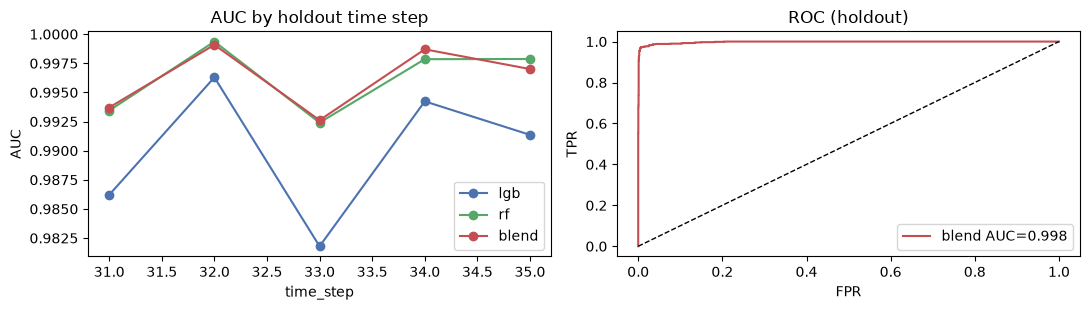

In [8]:
rows = []
for s in sorted(va.time_step.unique()):
    m = (va.time_step == s).values; ys = yva[m]
    if 0 < ys.sum() < len(ys):
        rows.append((s, roc_auc_score(ys, p_lgb[m]), roc_auc_score(ys, p_rf[m]),
                     roc_auc_score(ys, p_blend3[m]), int(ys.sum()), len(ys)))
per_step = pd.DataFrame(rows, columns=["step", "lgb", "rf", "blend", "illicit", "n"]).set_index("step")
print(per_step.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for c, col in [("lgb", "#4C72B0"), ("rf", "#55A868"), ("blend", "#C44E52")]:
    ax[0].plot(per_step.index, per_step[c], marker="o", label=c, color=col)
ax[0].set_title("AUC by holdout time step"); ax[0].set_xlabel("time_step"); ax[0].set_ylabel("AUC"); ax[0].legend()
fpr, tpr, _ = roc_curve(yva, p_blend3)
ax[1].plot(fpr, tpr, color="#C44E52", label=f"blend AUC={results['Blend LGB+XGB+RF (final family)']:.3f}")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC (holdout)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
plt.tight_layout(); plt.show()

### 4.2 Feature importance (LightGBM, raw+graph)

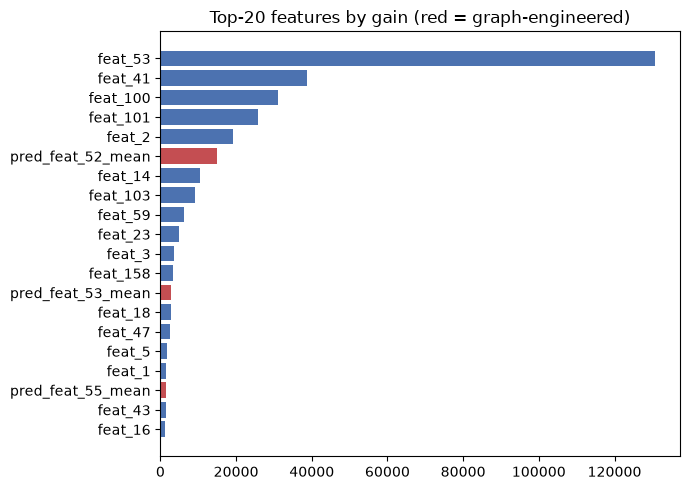

graph-engineered features in top 50: 10


In [9]:
imp = pd.Series(m_lgb.feature_importance(importance_type="gain"), index=FEAT_COLS).sort_values(ascending=False)
top = imp.head(20)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color=["#C44E52" if c in GRAPH_COLS else "#4C72B0" for c in top.index])
plt.title("Top-20 features by gain (red = graph-engineered)"); plt.tight_layout(); plt.show()
print("graph-engineered features in top 50:", sum(c in GRAPH_COLS for c in imp.head(50).index))

### 4.3 Public-leaderboard evidence (model selection)

Because the holdout is saturated (and, for model *ranking*, anti-correlated with the real test —
Random Forest was best on the holdout but worst on the leaderboard), we selected the final model on
the Kaggle **public leaderboard** (30% of the test set, the hard future steps 36–49). The progression:

| Submission | Public-LB AUC |
|---|---|
| Random Forest (raw+graph) | 0.9390 |
| LightGBM (raw+graph) | 0.9443 |
| Blend LGB+RF | 0.9449 |
| Blend LGB+XGB+RF | 0.9498 |
| Blend LGB+XGB (raw+graph) | 0.9503 |
| **Blend LGB+XGB + structural features** | **0.9514** |

Key findings — several the *opposite* of what the saturated holdout suggests, which is why the public
LB mattered:
* On the future steps, **boosting beats bagging** (LightGBM/XGBoost > Random Forest), reversing the
  holdout ordering.
* **Learner diversity drove the gains**: adding XGBoost (only ~0.82 rank-correlated with LightGBM)
  lifted the blend by ~0.005.
* **Beyond-1-hop structural features** added the final ~0.001; 1-hop features did not (they duplicate
  the dataset's own aggregates).
* Things that did **not** help, confirmed on the LB: a GraphSAGE **GNN** (individually weaker than the
  trees and only ~0.4–0.5 rank-correlated — its diversity was noise, so blending it in hurt), heavier
  **regularization**, and recency weighting (within noise). These are reported as negative results.

The cells below regenerate **both** submissions selected for the final private leaderboard, each a
rank-average blend of LightGBM + XGBoost that differs only in the feature set: the primary on
raw + graph + structural features (`cand_struct_lgb_xgb.csv`), and the hedge on raw + graph features
only (`cand_blend_lgb_xgb.csv`).

## 5. Final models and submissions

### 5.1 Fit final models on all labeled data and regenerate both submissions

In [10]:
# Regenerate BOTH submissions selected for the final private leaderboard. Each is a rank-average
# blend of LightGBM + XGBoost refit on ALL labeled rows; they differ only in the feature set:
#   cand_struct_lgb_xgb.csv (primary) -> raw + graph + structural features (FULL_COLS)
#   cand_blend_lgb_xgb.csv  (hedge)   -> raw + graph features only         (FEAT_COLS)
y_all = lab["label"].astype(int).values

def fit_blend_and_write(cols, holdout_model, filename):
    params = dict(objective="binary", metric="auc", learning_rate=0.02, num_leaves=64,
                  min_child_samples=50, feature_fraction=0.7, bagging_fraction=0.7, bagging_freq=1,
                  scale_pos_weight=scale_pos_weight(y_all), seed=SEED, verbosity=-1)
    final_lgb = lgb.train(params, lgb.Dataset(lab[cols], y_all),
                          num_boost_round=max(holdout_model.best_iteration, 100))
    final_xgb = train_xgb(lab, cols)
    p_lgb = final_lgb.predict(test[cols])
    p_xgb = final_xgb.predict_proba(test[cols].fillna(0))[:, 1]
    sub = pd.DataFrame({"index": test["index"].values, "target": rank_average([p_lgb, p_xgb])})
    sub.to_csv(SUB_DIR / filename, index=False)
    print("wrote", (SUB_DIR / filename).resolve())
    return sub

# primary: raw + graph + structural (m_full tunes the iteration count on the temporal holdout)
m_full = train_lightgbm(tr, va, FULL_COLS)
submission = fit_blend_and_write(FULL_COLS, m_full, "cand_struct_lgb_xgb.csv")

# hedge: raw + graph only (m_lgb, the FEAT_COLS holdout fit, was trained in section 4)
submission_hedge = fit_blend_and_write(FEAT_COLS, m_lgb, "cand_blend_lgb_xgb.csv")

submission.head()

Training until validation scores don't improve for 100 rounds


Early stopping, best iteration is:
[8]	valid's auc: 0.993946


wrote /Users/I777832/bt4012_competition/submissions/cand_struct_lgb_xgb.csv


wrote /Users/I777832/bt4012_competition/submissions/cand_blend_lgb_xgb.csv


,index,target
0,0,0.350936
1,1,0.595701
2,2,0.491356
3,3,0.353578
4,4,0.473710


### 5.2 Validate submission format

In [11]:
samp = pd.read_csv(DATA_DIR / "sample_submission.csv")
for name, sub in [("cand_struct_lgb_xgb.csv", submission), ("cand_blend_lgb_xgb.csv", submission_hedge)]:
    assert list(sub.columns) == ["index", "target"]
    assert len(sub) == len(samp) == 15329
    assert set(sub["index"]) == set(samp["index"]) and sub["index"].is_unique
    assert sub["target"].between(0, 1).all() and sub["target"].notna().all()
    print(f"{name} valid:", sub.shape, "| target range",
          (round(sub.target.min(), 4), round(sub.target.max(), 4)))

cand_struct_lgb_xgb.csv valid: (15329, 2) | target range (np.float64(0.0127), np.float64(0.9997))
cand_blend_lgb_xgb.csv valid: (15329, 2) | target range (np.float64(0.0101), np.float64(0.9998))


## 6. Conclusion and reflection

* **Raw features are highly predictive**: tree models reach ~0.99 holdout AUC on steps 31–35,
  comfortably beating the logistic-regression baseline (~0.92). The main challenge is not fitting
  the labeled data but **generalizing to future steps** past the dark-market shutdown — on the
  public leaderboard (steps 36–49) the best model scores ~0.951, a realistic gap from the saturated
  holdout.
* **The saturated holdout can mislead**: it ranked Random Forest first, but on the real future
  steps **boosting beat bagging** — the public LB was essential for honest model selection.
* **Learner diversity was the biggest lever**: blending LightGBM + XGBoost (weakly-correlated
  learners) lifted public-LB AUC from ~0.944 to ~0.950.
* **Graph structure shaped the design**: the time-partitioned graph (0 train↔test edges) rules out
  label propagation into the future and dictates a within-time-step, inductive view of graph signal.
  Beyond-1-hop **structural features** (embeddings + PageRank/clustering/hop2) added the final lift
  to ~0.951; 1-hop features did not, because the dataset already encodes 1-hop aggregates.
* **Negative results (useful findings)**: an inductive GraphSAGE **GNN** was individually weaker than
  the trees and too differently-wrong to help the blend; heavier **regularization** and recency
  weighting did not beat the defaults. We kept the simpler, stronger tree blend.
* **Final model**: a rank-average blend of LightGBM + XGBoost on raw + graph + structural features.
* **Possible extensions**: temporal GNNs (e.g. EvolveGCN) designed for distribution shift,
  motif/subgraph-count features, and pseudo-labeling within train time steps.